# UrbanBike – Explorative Datenanalyse mit NumPy und pandas

**Grundlagen des Maschinellen Lernens · Woche 2**

Der Datensatz enthält synthetische Fahrradbuchungen. Die Beispiele zeigen typische Schritte der explorativen Datenanalyse und einfache Transformationen mit Python.

Öffnen Sie das Notebook in Jupyter und führen Sie die Zellen nacheinander mit **Shift + Enter** aus.

## 0. Vorbereitung

Benötigte Bibliotheken: `numpy`, `pandas` und `matplotlib`.

Legen Sie die Datei `UrbanBike_EDA.csv` in den Arbeitsordner des Notebooks. In Google Colab können Sie die Datei über die Dateileiste hochladen.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 110)

DATA = Path('UrbanBike_EDA.csv')
if not DATA.is_file():
    raise FileNotFoundError(
        'UrbanBike_EDA.csv fehlt. Bitte genau diese Datei in denselben Arbeitsordner '
        'wie das Notebook legen (oder in Colab hochladen).'
    )
print('Eingelesene Datei:', DATA.name)
print('Arbeitsordner:', Path.cwd())


Eingelesene Datei: UrbanBike_EDA.csv
Arbeitsordner: /Users/julianahuppertz/Documents/Beruflich/Nordakademie/03_Vorlesungen/Grundlagen des maschinellen Lernens


In [ ]:
## Test Pygwalker
# %pip install pygwalker


In [ ]:
#import pygwalker as pyg


## 1. Daten einlesen und erste Orientierung

Jede Zeile bezeichnet eine Fahrradbuchung; die Spalten enthalten Messwerte, Kategorien, Zeitpunkte oder Texte. Der Zielindikator `reklamation_7tage` kennzeichnet, ob binnen sieben Tagen eine Reklamation auftrat (0 = nein, 1 = ja).


In [2]:
df = pd.read_csv(DATA)
print('Zeilen und Spalten:', df.shape)
display(df.head(5))


Zeilen und Spalten: (842, 14)


,buchung_id,startzeit,fahrrad_id,zone,kundenstatus,temperatur_c,niederschlag_mm,akku_start_pct,tage_seit_wartung,bisherige_buchungen,strecke_km,fahrtdauer_min,feedback_nach_fahrt,reklamation_7tage
0,B00494,2025-01-01 07:34:00,UB-015,Sued,Stammkunde,-3.7,0.5,100.0,52,12,1.5,3.5,Zufrieden mit der Ausleihe,0
1,B00141,2025-01-01 09:08:00,UB-031,Zentrum,Abo,-3.3,0.0,69.0,118,17,3.1,8.5,Fahrt ruhig und angenehm,0
2,B00419,2025-01-01 10:59:00,UB-021,Sued,Stammkunde,-3.2,0.0,91.0,8,16,16.7,78.4,Fahrt ruhig und angenehm,0
3,B00709,2025-01-01 13:27:00,UB-035,Nord,Stammkunde,-2.9,0.8,100.0,62,11,3.4,19.2,Buchung hat gut funktioniert,0
4,B00204,2025-01-01 16:24:00,UB-016,Zentrum,Neukunde,12.7,1.0,32.0,108,5,2.4,14.7,Rückgabe über die App schwierig,1


In [3]:
# Spaltennamen, Informationen über Datentypen und erste Zahlenübersicht
print('Spaltennamen:')
print(df.columns.tolist())
print('\nDatenstruktur:')
df.info()


Spaltennamen:
['buchung_id', 'startzeit', 'fahrrad_id', 'zone', 'kundenstatus', 'temperatur_c', 'niederschlag_mm', 'akku_start_pct', 'tage_seit_wartung', 'bisherige_buchungen', 'strecke_km', 'fahrtdauer_min', 'feedback_nach_fahrt', 'reklamation_7tage']

Datenstruktur:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 842 entries, 0 to 841
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   buchung_id           842 non-null    object 
 1   startzeit            842 non-null    object 
 2   fahrrad_id           842 non-null    object 
 3   zone                 825 non-null    object 
 4   kundenstatus         842 non-null    object 
 5   temperatur_c         818 non-null    float64
 6   niederschlag_mm      842 non-null    float64
 7   akku_start_pct       804 non-null    float64
 8   tage_seit_wartung    842 non-null    int64  
 9   bisherige_buchungen  842 non-null    int64  
 10  strecke_km           

In [ ]:
# Dataframe kopieren (mit deep)
df_copy = df.copy(deep = True)

In [ ]:
df['eins'] = 1

In [ ]:
df['eins']

### 1.1 Daten mit `read_csv()` einlesen

`pd.read_csv()` liest eine CSV-Datei als DataFrame ein. Mit `head()`, `shape`, `info()` und `columns` erhalten Sie eine erste Übersicht.

In [4]:
print('Anzahl Zeilen / Spalten:', df.shape)
print('Erste drei Buchungen:')
display(df.head(3))
print('Alle Spalten:', df.columns.tolist())


Anzahl Zeilen / Spalten: (842, 14)
Erste drei Buchungen:


,buchung_id,startzeit,fahrrad_id,zone,kundenstatus,temperatur_c,niederschlag_mm,akku_start_pct,tage_seit_wartung,bisherige_buchungen,strecke_km,fahrtdauer_min,feedback_nach_fahrt,reklamation_7tage
0,B00494,2025-01-01 07:34:00,UB-015,Sued,Stammkunde,-3.7,0.5,100.0,52,12,1.5,3.5,Zufrieden mit der Ausleihe,0
1,B00141,2025-01-01 09:08:00,UB-031,Zentrum,Abo,-3.3,0.0,69.0,118,17,3.1,8.5,Fahrt ruhig und angenehm,0
2,B00419,2025-01-01 10:59:00,UB-021,Sued,Stammkunde,-3.2,0.0,91.0,8,16,16.7,78.4,Fahrt ruhig und angenehm,0


Alle Spalten: ['buchung_id', 'startzeit', 'fahrrad_id', 'zone', 'kundenstatus', 'temperatur_c', 'niederschlag_mm', 'akku_start_pct', 'tage_seit_wartung', 'bisherige_buchungen', 'strecke_km', 'fahrtdauer_min', 'feedback_nach_fahrt', 'reklamation_7tage']


## 2. NumPy- und pandas-Grundfunktionen

**NumPy** verwendet insbesondere Arrays mit Positionsindizes. **pandas** stellt eine tabellarische Datenstruktur (`DataFrame`) mit Spaltennamen und Zeilenindizes bereit.

Python beginnt beim Positionszählen mit **0**: `a[0]` bezeichnet das erste Element.


In [5]:
a = np.array([18.2, 19.0, 17.6, 20.1])
print('Array:', a)
print('Erstes Element a[0]:', a[0])
print('Drittes Element a[2]:', a[2])
print('Letztes Element a[-1]:', a[-1])
print('Ausschnitt a[1:3]:', a[1:3])
print('Mittelwert:', np.mean(a))


Array: [18.2 19.  17.6 20.1]
Erstes Element a[0]: 18.2
Drittes Element a[2]: 17.6
Letztes Element a[-1]: 20.1
Ausschnitt a[1:3]: [19.  17.6]
Mittelwert: 18.725


In [6]:
# Zwei NumPy-Arrays zu einer Tabelle zusammenführen
standorte = np.array(['Nord', 'Süd', 'West'])
temperaturen = np.array([18.2, 19.0, 17.6])
X = np.column_stack([standorte, temperaturen])
print('NumPy-Matrix (wegen gemischter Inhalte hier alles als Text):')
print(X)

# Mit pandas bleiben Zahlen und Kategorien in ihren passenden Datentypen:
beispiel_df = pd.DataFrame({'zone': standorte, 'temperatur_c': temperaturen})
display(beispiel_df)


NumPy-Matrix (wegen gemischter Inhalte hier alles als Text):
[['Nord' '18.2']
 ['Süd' '19.0']
 ['West' '17.6']]


,zone,temperatur_c
0,Nord,18.2
1,Süd,19.0
2,West,17.6


### 2.1 Mit pandas einzelne Elemente und Spalten auswählen

- `df['zone']`: eine Spalte als `Series`.
- `df[['zone', 'temperatur_c']]`: zwei Spalten als `DataFrame`.
- `df.iloc[2, 5]`: dritte Zeile, sechste Spalte **nach Position**.
- `df.loc[2, 'temperatur_c']`: Wert anhand von Zeilenlabel und Spaltenname (hier ist das Label zufällig 2).


In [7]:
display(df['zone'].head())
display(df[['zone', 'temperatur_c']].head())
print('Dritte Zeile, sechste Spalte:', df.iloc[2, 5])
print('Zeilenlabel 2, Spalte temperatur_c:', df.loc[2, 'temperatur_c'])
print('Buchungen mit einer Temperatur über 20 °C:', (df['temperatur_c'] > 20).sum())
display(df.loc[df['temperatur_c'] > 20, ['zone', 'temperatur_c']].head())


0       Sued
1    Zentrum
2       Sued
3       Nord
4    Zentrum
Name: zone, dtype: object

,zone,temperatur_c
0,Sued,-3.7
1,Zentrum,-3.3
2,Sued,-3.2
3,Nord,-2.9
4,Zentrum,12.7


Dritte Zeile, sechste Spalte: -3.2
Zeilenlabel 2, Spalte temperatur_c: -3.2
Buchungen mit einer Temperatur über 20 °C: 105


,zone,temperatur_c
317,NaN,21.8
387,Nord,22.1
400,Zentrum,87.5
409,Sued,20.4
427,Nord,20.6


## 2.2 Python-Datentypen – alle neun Typen aus der Vorlesungsabbildung

**Wichtiger Unterschied:** Ein CSV-Datensatz besteht aus Textzeilen mit Trennzeichen. Beim Einlesen erkennt pandas beispielsweise Zahlen und Zeichenfolgen; Listen, Tupel, Mengen und Wörterbücher stehen **nicht automatisch** als Python-Objekte in einer CSV-Spalte. Solche Strukturen erzeugen wir daher **aus den eingelesenen UrbanBike-Werten**.

| Python-Typ | Kurzbeschreibung | UrbanBike-Bezug |
|---|---|---|
| `int` | ganze Zahl | Anzahl bisheriger Buchungen |
| `float` | Kommazahl | Temperatur oder Fahrtdauer |
| `complex` | komplexe Zahl mit Real- und Imaginärteil | rein mathematisches Zusatzbeispiel; kein natürliches UrbanBike-Merkmal |
| `bool` | Wahrheitswert `True`/`False` | Reklamation vorhanden? |
| `str` | Zeichenkette | Zone, Feedback |
| `list` | veränderbare geordnete Sammlung | Temperaturwerte mehrerer Buchungen |
| `tuple` | unveränderbare geordnete Sammlung | Paar aus Temperatur und Niederschlag |
| `set` | Menge eindeutiger Elemente | vorhandene Ausleihgebiete |
| `dict` | Zuordnung von Schlüssel zu Wert | Häufigkeiten je Zone |

Die folgenden Zellen zeigen pro Typ **Erzeugung, typische Operationen und mindestens eine Umwandlung**.


In [8]:
# int, float: aus den CSV-Spalten ablesen und numerisch auswerten
ganze_zahl = int(df.loc[0, 'bisherige_buchungen'])
kommazahl = float(df.loc[0, 'temperatur_c'])
print('int:', ganze_zahl, '| Typ:', type(ganze_zahl).__name__)
print('float:', kommazahl, '| Typ:', type(kommazahl).__name__)
print('Rechnen:', ganze_zahl + 2, '| gerundete Temperatur:', round(kommazahl, 0))
print('Umwandlung float -> int (schneidet Nachkommastellen ab):', int(kommazahl))

# bool: binären Klassenwert in einen Wahrheitswert umwandeln
reklamiert = bool(df.loc[0, 'reklamation_7tage'] == 1)
print('\nbool:', reklamiert, '| NOT:', not reklamiert)
print('Anzahl der Reklamationen (Vergleich über alle Zeilen):',
      int(df['reklamation_7tage'].eq(1).sum()))

# complex: allgemeiner Python-Typ, für diese EDA kein sinnvoller Featuretyp
komplexe_zahl = 2 + 3j
print('\ncomplex:', komplexe_zahl, 'Realteil:', komplexe_zahl.real,
      'Imaginärteil:', komplexe_zahl.imag, 'Betrag:', abs(komplexe_zahl))


int: 12 | Typ: int
float: -3.7 | Typ: float
Rechnen: 14 | gerundete Temperatur: -4.0
Umwandlung float -> int (schneidet Nachkommastellen ab): -3

bool: False | NOT: True
Anzahl der Reklamationen (Vergleich über alle Zeilen): 72

complex: (2+3j) Realteil: 2.0 Imaginärteil: 3.0 Betrag: 3.605551275463989


In [9]:
# str: Zeichenketten aus der CSV
zone_text = str(df.loc[0, 'zone'])
print('str:', zone_text, '| Länge:', len(zone_text))
print('Kleinbuchstaben:', zone_text.lower(), '| erste zwei Zeichen:', zone_text[:2])
print('Teilstring ersetzen:', zone_text.replace('Sued', 'Süd'))

# Series.str wendet Zeichenketten-Operationen auf eine ganze Spalte an.
print('\nBeispiel: Feedbacktexte in Kleinbuchstaben')
display(df['feedback_nach_fahrt'].dropna().astype(str).str.lower().head(3))


str: Sued | Länge: 4
Kleinbuchstaben: sued | erste zwei Zeichen: Su
Teilstring ersetzen: Süd

Beispiel: Feedbacktexte in Kleinbuchstaben


0    zufrieden mit der ausleihe
1      fahrt ruhig und angenehm
2      fahrt ruhig und angenehm
Name: feedback_nach_fahrt, dtype: object

In [10]:
# list: geordnete, veränderbare Sammlung
werte_liste = df['temperatur_c'].dropna().head(5).tolist()
print('list:', werte_liste)
print('erstes Element [0]:', werte_liste[0], '| letztes [-1]:', werte_liste[-1])
print('Anzahl:', len(werte_liste), '| Mittelwert:', round(np.mean(werte_liste), 2))
werte_liste.append(20.0)  # list ist veränderbar
print('nach append:', werte_liste)

# tuple: geordnet, aber nicht veränderbar; Beispiel: zwei Messgrößen einer Buchung
messpaar = (float(df.loc[0, 'temperatur_c']), float(df.loc[0, 'niederschlag_mm']))
print('\ntuple (Temperatur, Niederschlag):', messpaar)
print('zweites Element:', messpaar[1], '| Länge:', len(messpaar))
print('tuple -> list:', list(messpaar))

# set: eine ungeordnete Sammlung ohne doppelte Werte
gebiete_menge = set(df['zone'].dropna().astype(str))
print('\nset: verschiedene Schreibweisen in der Original-CSV:', sorted(gebiete_menge))
print('Anzahl unterschiedlicher Werte:', len(gebiete_menge))
print('Kommt Zentrum vor?', 'Zentrum' in gebiete_menge)
print('set -> sortierte list:', sorted(gebiete_menge))

# dict: Schlüssel-Wert-Paare; hier Zone -> Häufigkeit
haeufigkeit_je_zone = df['zone'].value_counts().to_dict()
print('\ndict:', haeufigkeit_je_zone)
print('Wert für Zentrum:', haeufigkeit_je_zone.get('Zentrum', 0))
print('Schlüssel:', list(haeufigkeit_je_zone.keys()))
print('dict -> DataFrame:')
display(pd.DataFrame(list(haeufigkeit_je_zone.items()), columns=['Zone','Anzahl']))


list: [-3.7, -3.3, -3.2, -2.9, 12.7]
erstes Element [0]: -3.7 | letztes [-1]: 12.7
Anzahl: 5 | Mittelwert: -0.08
nach append: [-3.7, -3.3, -3.2, -2.9, 12.7, 20.0]

tuple (Temperatur, Niederschlag): (-3.7, 0.5)
zweites Element: 0.5 | Länge: 2
tuple -> list: [-3.7, 0.5]

set: verschiedene Schreibweisen in der Original-CSV: ['Nord', 'Sued', 'West', 'Zentrum']
Anzahl unterschiedlicher Werte: 4
Kommt Zentrum vor? True
set -> sortierte list: ['Nord', 'Sued', 'West', 'Zentrum']

dict: {'Zentrum': 345, 'West': 172, 'Nord': 163, 'Sued': 145}
Wert für Zentrum: 345
Schlüssel: ['Zentrum', 'West', 'Nord', 'Sued']
dict -> DataFrame:


,Zone,Anzahl
0,Zentrum,345
1,West,172
2,Nord,163
3,Sued,145


### Die neun Python-Typen im Überblick

Die Übungsbeispiele zeigen neun tatsächliche Python-Objekte. **Nicht verwechseln:** Eine statistische *kategoriale Variable* ist eine Bedeutungsebene. Sie wird in pandas oft zunächst als `object` (meist Zeichenkette) eingelesen und kann danach in den Datentyp `category` konvertiert werden.

```python
# Typ eines einzelnen Python-Objekts
type(werte_liste)
# Typen aller Spalten eines DataFrames
df.dtypes
```

Für die EDA der CSV unterscheiden wir im folgenden Kapitel zusätzlich **metrische, kategoriale, binäre, zeitliche und textuelle Merkmale**.


## 3. Variablentypen und Datenqualität

**Unterscheidung der Ebenen:**

- **Numerisch / metrisch:** z. B. Temperatur, Strecke, Fahrtdauer.
- **Kategorial / nominal:** z. B. Zone, Kundenstatus. `reklamation_7tage` ist ein binäres Klassenmerkmal.
- **Zeitlich:** `startzeit`; kann als Zeitpunkt interpretiert und in Stunden oder Wochentage zerlegt werden.
- **Textuell:** `feedback_nach_fahrt`; nicht ohne Weiteres eine numerische Modellvariable.
- **Identifikatoren:** `buchung_id`, `fahrrad_id`; Zeichenfolgen mit einer fachlichen Identifikationsfunktion.

Der in pandas angezeigte Datentyp `object` bedeutet nicht automatisch „kategorial“: Auch Zeitstempel oder längere Texte werden beim CSV-Import zunächst oft als Zeichenfolgen erkannt.


In [11]:
print('Datentypen direkt nach dem Einlesen:')
print(df.dtypes)

# Kopie anlegen – Originaldaten bleiben unverändert.
eda = df.copy()
eda['startzeit'] = pd.to_datetime(eda['startzeit'], errors='coerce')
eda['zone'] = eda['zone'].replace({'Sued': 'Süd'}).astype('category')
eda['kundenstatus'] = eda['kundenstatus'].replace('?', pd.NA).astype('category')
print('\nDatentypen nach der Umwandlung:')
print(eda[['startzeit', 'zone', 'kundenstatus']].dtypes)


Datentypen direkt nach dem Einlesen:
buchung_id              object
startzeit               object
fahrrad_id              object
zone                    object
kundenstatus            object
temperatur_c           float64
niederschlag_mm        float64
akku_start_pct         float64
tage_seit_wartung        int64
bisherige_buchungen      int64
strecke_km             float64
fahrtdauer_min         float64
feedback_nach_fahrt     object
reklamation_7tage        int64
dtype: object

Datentypen nach der Umwandlung:
startzeit       datetime64[ns]
zone                  category
kundenstatus          category
dtype: object


### 3.0 Merkmalsarten im UrbanBike-Datensatz untersuchen

Im Gegensatz zu den neun *Python-Objekttypen* geht es hier um die **fachliche Einordnung der Tabellenspalten**. Wir verwenden die vorhandenen Daten, ohne etwas nachzuladen:

- **Metrisch:** Temperatur, Fahrtdauer, Akkuladung → `describe()`, Mittelwert, Histogramm.
- **Diskret numerisch:** Anzahl bisheriger Buchungen, Tage seit Wartung → Häufigkeit, Median, Summen.
- **Nominal:** Zone, Kundenstatus → `value_counts()`, `groupby()`.
- **Binär:** Reklamation `0`/`1` → Anteil der Reklamationen.
- **Zeitlich:** Startzeit → Zeitstempel konvertieren, Wochentag/Stunde ableiten.
- **Textuell:** Feedback → Zeichenlänge und Wortsuche.
- **Identifikatoren:** Buchung-/Fahrrad-ID → Eindeutigkeit und Duplikate prüfen; keine Mittelwerte bilden.


In [12]:
# Die Merkmalsarten im echten UrbanBike-DataFrame gezielt untersuchen
metrisch = ['temperatur_c', 'niederschlag_mm', 'akku_start_pct',
            'strecke_km', 'fahrtdauer_min']
diskret = ['tage_seit_wartung', 'bisherige_buchungen']
kategorial = ['zone', 'kundenstatus']
binaer = 'reklamation_7tage'
zeitlich = 'startzeit'
textuell = 'feedback_nach_fahrt'

print('Metrische Merkmale – Kennzahlen:')
display(eda[metrisch].describe().round(2))
print('Diskrete Zählmerkmale – Typ und Wertebeispiele:')
display(eda[diskret].head(3))
print('Kategoriale Merkmale – Häufigkeiten:')
for spalte in kategorial:
    print(spalte)
    display(eda[spalte].value_counts(dropna=False).head(8))
print('Binäres Zielmerkmal – Werte:', eda[binaer].value_counts(dropna=False).to_dict())
print('Zeitmerkmal – Datentyp:', eda[zeitlich].dtype)
print('Textmerkmal – Zeichenlängen:')
display(eda[textuell].dropna().astype(str).str.len().describe().round(1))


Metrische Merkmale – Kennzahlen:


,temperatur_c,niederschlag_mm,akku_start_pct,strecke_km,fahrtdauer_min
count,818.00,842.00,804.00,842.00,842.00
mean,11.71,1.06,66.07,4.42,22.50
std,8.13,1.63,19.55,2.83,13.38
min,-12.00,0.00,5.00,-3.40,2.00
25%,6.30,0.00,53.00,2.40,13.60
50%,12.20,0.20,66.00,3.80,20.10
75%,17.40,1.70,81.00,5.80,29.00
max,87.50,13.80,100.00,18.60,82.70


Diskrete Zählmerkmale – Typ und Wertebeispiele:


,tage_seit_wartung,bisherige_buchungen
0,52,12
1,118,17
2,8,16


Kategoriale Merkmale – Häufigkeiten:
zone


zone
Zentrum    345
West       172
Nord       163
Süd        145
NaN         17
Name: count, dtype: int64

kundenstatus


kundenstatus
Stammkunde    401
Neukunde      230
Abo           182
NaN            29
Name: count, dtype: int64

Binäres Zielmerkmal – Werte: {0: 770, 1: 72}
Zeitmerkmal – Datentyp: datetime64[ns]
Textmerkmal – Zeichenlängen:


count    807.0
mean      27.9
std        3.5
min       24.0
25%       26.0
50%       28.0
75%       32.0
max       38.0
Name: feedback_nach_fahrt, dtype: float64

### 3.0.1 Merkmalsarten in neue Features umwandeln

Diese Schritte verwenden weiterhin nur den bereits geladenen DataFrame. Die neue Spalte `temperaturklasse` ist beispielsweise **kategorial**, obwohl ihre Ausgangsspalte `temperatur_c` metrisch ist.

In [14]:
# Weitere Transformationen der vorhandenen Feature-Typen
transform = eda[['temperatur_c', 'zone', 'reklamation_7tage',
                 'startzeit', 'feedback_nach_fahrt']].copy()

# Metrisch -> geordnete Kategorie
transform['temperaturklasse'] = pd.cut(
    transform['temperatur_c'], bins=[-np.inf, 0, 20, np.inf],
    labels=['kalt', 'mild', 'warm'])

# Kategorial -> binäre Indikatorspalte (True/False)
transform['zone_zentrum'] = transform['zone'].eq('Zentrum')

# Numerisch 0/1 -> bool (Wahrheitswert)
transform['rekla_bool'] = transform['reklamation_7tage'].eq(1)

# Zeitpunkt -> Wochentag
transform['wochentag_nr'] = transform['startzeit'].dt.dayofweek

# Text -> einfache Kennzahl
transform['feedback_woerter'] = transform['feedback_nach_fahrt'].fillna('').str.split().str.len()

print('Abgeleitete Features und Datentypen:')
display(transform[['temperatur_c','temperaturklasse','zone_zentrum','rekla_bool',
                   'wochentag_nr','feedback_woerter']].head(8))
print(transform[['temperaturklasse','zone_zentrum','rekla_bool',
                 'wochentag_nr','feedback_woerter']].dtypes)


Abgeleitete Features und Datentypen:


,temperatur_c,temperaturklasse,zone_zentrum,rekla_bool,wochentag_nr,feedback_woerter
0,-3.7,kalt,False,False,2,4
1,-3.3,kalt,True,False,2,4
2,-3.2,kalt,False,False,2,4
3,-2.9,kalt,False,False,2,4
4,12.7,mild,True,True,2,5
5,-7.7,kalt,True,False,2,4
6,-1.3,kalt,False,False,3,4
7,-0.5,kalt,True,False,3,4


temperaturklasse    category
zone_zentrum            bool
rekla_bool              bool
wochentag_nr           int32
feedback_woerter       int64
dtype: object


In [13]:
import seaborn as sns

ModuleNotFoundError: No module named 'seaborn'

In [ ]:
%pip install seaborn

### 3.1 Fehlende Werte und Sondercodes

`isna()` erkennt tatsächliche fehlende Werte (`NaN`, `NA`), **nicht** automatisch alle textuellen Platzhalter wie `?`. Daher muss der Kundenstatus ausdrücklich überprüft werden.


In [15]:
fehlwerte = pd.DataFrame({
    'Anzahl_fehlend': eda.isna().sum(),
    'Anteil_in_%': eda.isna().mean().mul(100).round(1)
})
display(fehlwerte.loc[fehlwerte['Anzahl_fehlend'] > 0].sort_values('Anzahl_fehlend', ascending=False))
print('Fehlende Kundenstatus-Werte nach Ersetzen von ?: ', eda['kundenstatus'].isna().sum())


,Anzahl_fehlend,Anteil_in_%
akku_start_pct,38,4.5
feedback_nach_fahrt,35,4.2
kundenstatus,29,3.4
temperatur_c,24,2.9
zone,17,2.0


Fehlende Kundenstatus-Werte nach Ersetzen von ?:  29


### 3.2 Duplikate

Ein Duplikat kann eine vollständig identische Zeile sein oder ein mehrfach vorkommender Buchungsschlüssel. Die beiden Prüfungen sind nicht gleichbedeutend.


In [16]:
print('Vollständig doppelte Zeilen:', eda.duplicated().sum())
print('Wiederholte buchung_id:', eda['buchung_id'].duplicated().sum())
display(eda.loc[eda['buchung_id'].duplicated(keep=False),
                ['buchung_id', 'startzeit', 'zone', 'fahrtdauer_min']].sort_values('buchung_id'))


Vollständig doppelte Zeilen: 2
Wiederholte buchung_id: 2


,buchung_id,startzeit,zone,fahrtdauer_min
45,B00227,2025-01-08 18:12:00,West,38.9
46,B00227,2025-01-08 18:12:00,West,38.9
311,B00831,2025-03-04 16:14:00,Zentrum,13.0
312,B00831,2025-03-04 16:14:00,Zentrum,13.0


### 3.3 Plausible Wertebereiche und Ausreißer

Ein ungewöhnlicher Wert ist **nicht automatisch** ein Messfehler. Im Lehrdatensatz sind allerdings auch offensichtlich unplausible Werte enthalten (z. B. negative Streckenlängen). Untersuchen Sie die Einzelfälle zunächst, bevor Sie sie korrigieren.


In [17]:
auffaellig = eda.loc[
    (eda['temperatur_c'] > 45) |
    (eda['strecke_km'] < 0),
    ['buchung_id', 'temperatur_c', 'strecke_km', 'fahrtdauer_min']
]
display(auffaellig)

# Für manche Grafiken erstellen wir eine separate fachlich plausible Teilmenge.
plausibel = eda.loc[eda['temperatur_c'].between(-30, 45) &
                    eda['strecke_km'].ge(0)].copy()
print('Zeilen in der plausibilisierten Teilmenge:', len(plausibel))


,buchung_id,temperatur_c,strecke_km,fahrtdauer_min
170,B00491,8.5,-3.4,21.2
400,B00541,87.5,3.6,25.0


Zeilen in der plausibilisierten Teilmenge: 816


## 4. Deskriptive EDA: numerische Features

Wichtige Kennzahlen: Anzahl, Mittelwert, Standardabweichung, Minimum, Quartile, Maximum. Der **Median** ist gegenüber Extremwerten meist robuster als der Mittelwert.


In [18]:
num_cols = ['temperatur_c', 'niederschlag_mm', 'akku_start_pct',
            'strecke_km', 'fahrtdauer_min', 'tage_seit_wartung']
display(plausibel[num_cols].describe().round(2))

fahrt = plausibel['fahrtdauer_min'].dropna()
print('Mittelwert Fahrtdauer:', round(fahrt.mean(), 2), 'Minuten')
print('Median Fahrtdauer:', round(fahrt.median(), 2), 'Minuten')
print('IQR Fahrtdauer:', round(fahrt.quantile(.75) - fahrt.quantile(.25), 2), 'Minuten')


,temperatur_c,niederschlag_mm,akku_start_pct,strecke_km,fahrtdauer_min,tage_seit_wartung
count,816.00,816.00,779.00,816.00,816.00,816.00
mean,11.62,1.06,66.16,4.40,22.36,68.39
std,7.70,1.64,19.67,2.83,13.44,38.87
min,-12.00,0.00,5.00,0.30,2.00,1.00
25%,6.28,0.00,53.00,2.40,13.40,34.00
50%,12.20,0.20,66.00,3.80,19.90,70.00
75%,17.40,1.70,81.00,5.70,29.00,102.00
max,33.60,13.80,100.00,18.60,82.70,134.00


Mittelwert Fahrtdauer: 22.36 Minuten
Median Fahrtdauer: 19.9 Minuten
IQR Fahrtdauer: 15.6 Minuten


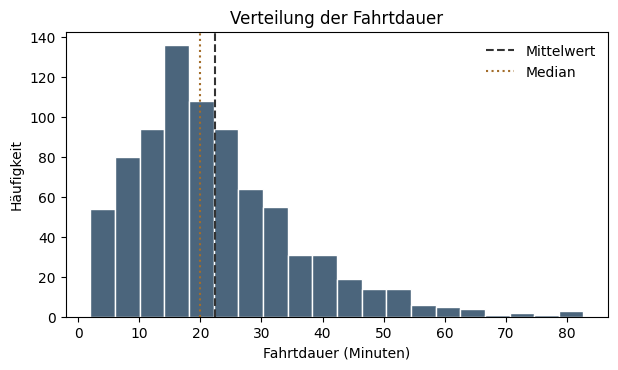

In [19]:
fig, ax = plt.subplots(figsize=(7, 3.7))
ax.hist(fahrt, bins=20, edgecolor='white', color='#4b657c')
ax.axvline(fahrt.mean(), color='#333333', linestyle='--', label='Mittelwert')
ax.axvline(fahrt.median(), color='#a36d2a', linestyle=':', label='Median')
ax.set(xlabel='Fahrtdauer (Minuten)', ylabel='Häufigkeit', title='Verteilung der Fahrtdauer')
ax.legend(frameon=False)
plt.show()


## 5. Deskriptive EDA: kategoriale Merkmale

Bei nominalen Merkmalen betrachten wir die Anzahl unterschiedlicher Kategorien, die absoluten Häufigkeiten und die relativen Häufigkeiten. Mittelwerte über nominale Kategoriecodes wären nicht sinnvoll.


Häufigkeiten Zone:


,Anzahl
zone,
Zentrum,345
West,172
Nord,163
Süd,145
NaN,17


Relative Häufigkeiten in Prozent:


,Anteil_%
zone,
Zentrum,41.0
West,20.4
Nord,19.4
Süd,17.2
NaN,2.0


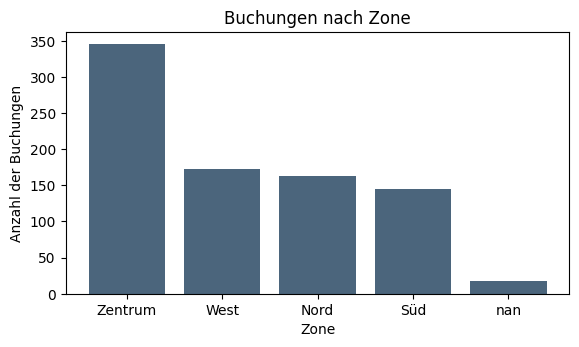

In [20]:
print('Häufigkeiten Zone:')
display(eda['zone'].value_counts(dropna=False).to_frame('Anzahl'))
print('Relative Häufigkeiten in Prozent:')
display(eda['zone'].value_counts(normalize=True, dropna=False).mul(100).round(1).to_frame('Anteil_%'))

counts = eda['zone'].value_counts(dropna=False)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.bar(counts.index.astype(str), counts.values, color='#4b657c')
ax.set(xlabel='Zone', ylabel='Anzahl der Buchungen', title='Buchungen nach Zone')
plt.show()


## 6. Textmerkmale und Zeitstempel

Für Text kann schon eine einfache erste Analyse nützlich sein: fehlende Einträge, Textlängen und Häufigkeiten der Antwortformulierungen. Für Zeitstempel lassen sich Kalendermerkmale ableiten und Buchungen über die Zeit aggregieren.


In [21]:
texte = eda['feedback_nach_fahrt'].dropna().astype(str)
print('Anzahl vorhandener Feedbacktexte:', len(texte))
print('Durchschnittliche Zeichenlänge:', round(texte.str.len().mean(), 1))
display(texte.value_counts().head(8).to_frame('Anzahl'))

eda['feedback_zeichen'] = eda['feedback_nach_fahrt'].fillna('').str.len()
eda['feedback_enthaelt_app'] = eda['feedback_nach_fahrt'].fillna('').str.contains('App', case=False)
display(eda[['feedback_nach_fahrt', 'feedback_zeichen', 'feedback_enthaelt_app']].head())


Anzahl vorhandener Feedbacktexte: 807
Durchschnittliche Zeichenlänge: 27.9


,Anzahl
feedback_nach_fahrt,
Fahrt ruhig und angenehm,192
Zufrieden mit der Ausleihe,188
Buchung hat gut funktioniert,183
Gute Verfügbarkeit der Fahrräder,174
Rückgabe über die App schwierig,19
Akkuanzeige war unzuverlässig,19
Fahrrad hatte ein mechanisches Problem,19
App zeigte mehrfach eine Fehlermeldung,13


,feedback_nach_fahrt,feedback_zeichen,feedback_enthaelt_app
0,Zufrieden mit der Ausleihe,26,False
1,Fahrt ruhig und angenehm,24,False
2,Fahrt ruhig und angenehm,24,False
3,Buchung hat gut funktioniert,28,False
4,Rückgabe über die App schwierig,31,True


,startzeit,datum,wochentag,stunde
0,2025-01-01 07:34:00,2025-01-01,Wednesday,7
1,2025-01-01 09:08:00,2025-01-01,Wednesday,9
2,2025-01-01 10:59:00,2025-01-01,Wednesday,10
3,2025-01-01 13:27:00,2025-01-01,Wednesday,13
4,2025-01-01 16:24:00,2025-01-01,Wednesday,16


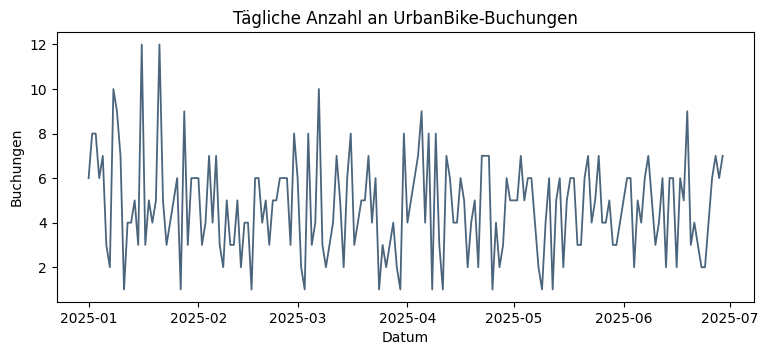

In [22]:
eda['datum'] = eda['startzeit'].dt.date
eda['wochentag'] = eda['startzeit'].dt.day_name()
eda['stunde'] = eda['startzeit'].dt.hour

display(eda[['startzeit', 'datum', 'wochentag', 'stunde']].head())

tagliche_buchungen = eda.groupby('datum').size()
fig, ax = plt.subplots(figsize=(9, 3.5))
tagliche_buchungen.plot(ax=ax, color='#4b657c', lw=1.3)
ax.set(xlabel='Datum', ylabel='Buchungen', title='Tägliche Anzahl an UrbanBike-Buchungen')
plt.show()


## 7. Bivariate EDA: Beziehungen zwischen Merkmalen

Eine bivariate Betrachtung untersucht zwei Variablen gleichzeitig. Hier reichen zunächst Scatterplots, Gruppenvergleiche, Korrelationen und Kreuztabellen; statistische Hypothesentests werden nicht benötigt.

**Achtung:** Der Pearson-Korrelationskoeffizient beschreibt nur einen *linearen* Zusammenhang. Ein statistischer Zusammenhang ist keine Aussage über Ursache und Wirkung.


Pearson-Korrelation Temperatur / Fahrtdauer: 0.034


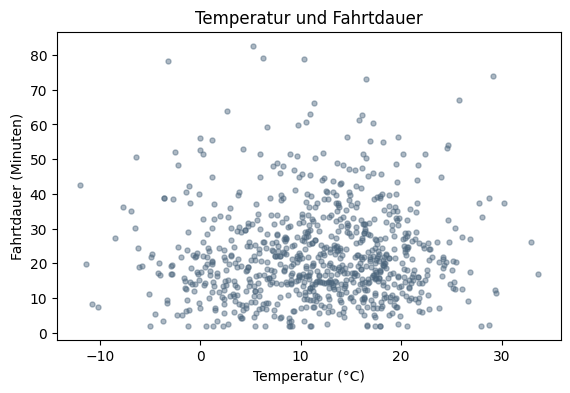

In [23]:
# Numerisch × numerisch
plot_df = plausibel[['temperatur_c', 'fahrtdauer_min']].dropna()
r = plot_df['temperatur_c'].corr(plot_df['fahrtdauer_min'])
print('Pearson-Korrelation Temperatur / Fahrtdauer:', round(r, 3))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(plot_df['temperatur_c'], plot_df['fahrtdauer_min'], s=13,
           alpha=0.45, color='#4b657c')
ax.set(xlabel='Temperatur (°C)', ylabel='Fahrtdauer (Minuten)',
       title='Temperatur und Fahrtdauer')
plt.show()


Fahrtdauer je Zone:


,count,mean,median,std
zone,,,,
Nord,158,21.59,18.80,12.77
Süd,140,23.28,22.00,13.12
West,167,25.18,22.20,13.92
Zentrum,334,21.16,18.35,13.63


TypeError: boxplot() got an unexpected keyword argument 'tick_labels'

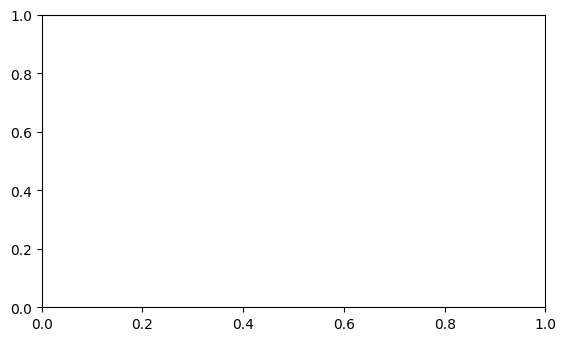

In [24]:
# Kategorial × numerisch: Gruppenstatistik
print('Fahrtdauer je Zone:')
display(plausibel.groupby('zone', observed=True)['fahrtdauer_min']
        .agg(['count', 'mean', 'median', 'std']).round(2))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
gruppen = [plausibel.loc[plausibel['zone'].eq(z), 'fahrtdauer_min'].dropna()
           for z in ['Zentrum', 'Nord', 'Süd', 'West']]
ax.boxplot(gruppen, tick_labels=['Zentrum', 'Nord', 'Süd', 'West'])
ax.set(xlabel='Zone', ylabel='Fahrtdauer (Minuten)',
       title='Fahrtdauer nach Ausleihgebiet')
plt.show()

## Fehlermeldung reduzieren

Fahrtdauer je Zone:


,count,mean,median,std
zone,,,,
Nord,158,21.59,18.80,12.77
Süd,140,23.28,22.00,13.12
West,167,25.18,22.20,13.92
Zentrum,334,21.16,18.35,13.63


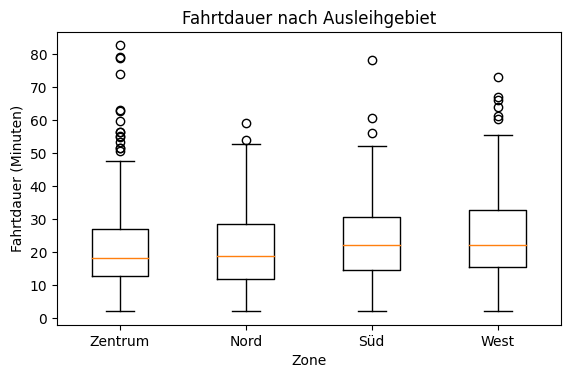

In [25]:
# Kategorial × numerisch: Gruppenstatistik
print('Fahrtdauer je Zone:')
display(plausibel.groupby('zone', observed=True)['fahrtdauer_min']
        .agg(['count', 'mean', 'median', 'std']).round(2))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
gruppen = [plausibel.loc[plausibel['zone'].eq(z), 'fahrtdauer_min'].dropna()
           for z in ['Zentrum', 'Nord', 'Süd', 'West']]
ax.boxplot(gruppen, labels=['Zentrum', 'Nord', 'Süd', 'West'])
ax.set(xlabel='Zone', ylabel='Fahrtdauer (Minuten)',
       title='Fahrtdauer nach Ausleihgebiet')
plt.show()

## Fehlermeldung reduzieren

In [26]:
# Kategorial × kategorial: Kreuztabelle
kreuz_abs = pd.crosstab(eda['kundenstatus'], eda['reklamation_7tage'])
kreuz_prozent = pd.crosstab(eda['kundenstatus'], eda['reklamation_7tage'],
                           normalize='index').mul(100).round(1)
print('Absolute Häufigkeiten:')
display(kreuz_abs)
print('Zeilenprozente:')
display(kreuz_prozent)


Absolute Häufigkeiten:


reklamation_7tage,0,1
kundenstatus,,
Abo,166,16
Neukunde,205,25
Stammkunde,372,29


Zeilenprozente:


reklamation_7tage,0,1
kundenstatus,,
Abo,91.2,8.8
Neukunde,89.1,10.9
Stammkunde,92.8,7.2


### 7.1 Mehrere Scatterplots: numerisch × numerisch

Ein **Scatterplot (Streudiagramm)** stellt zwei numerische Merkmale gemeinsam dar. Jeder Punkt entspricht einer Beobachtung.

Untersuchen Sie drei Merkmalskombinationen. Achten Sie auf Richtung, Form, Streuung, auffällige Werte und mögliche Gruppen. Ein Korrelationskoeffizient fasst nur den linearen Zusammenhang zusammen.

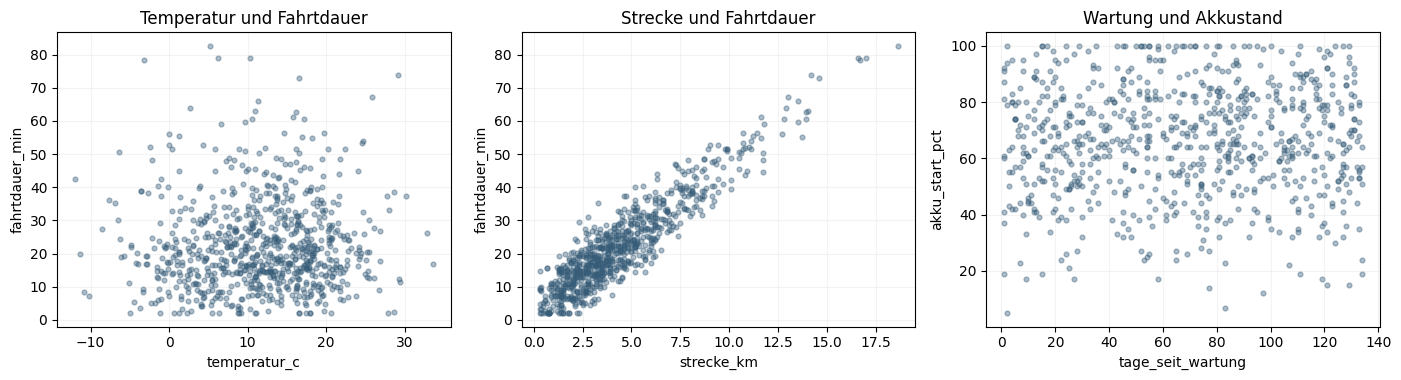

In [27]:
# Drei bivariate Streudiagramme auf plausiblen Beobachtungen
paare = [
    ('temperatur_c', 'fahrtdauer_min', 'Temperatur und Fahrtdauer'),
    ('strecke_km', 'fahrtdauer_min', 'Strecke und Fahrtdauer'),
    ('tage_seit_wartung', 'akku_start_pct', 'Wartung und Akkustand')
]

fig, achsen = plt.subplots(1, 3, figsize=(14, 3.9))
for ax, (x_spalte, y_spalte, titel) in zip(achsen, paare):
    werte = plausibel[[x_spalte, y_spalte]].dropna()
    ax.scatter(werte[x_spalte], werte[y_spalte], s=12, alpha=0.4, color='#365c78')
    ax.set(xlabel=x_spalte, ylabel=y_spalte, title=titel)
    ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

### 7.2 Korrelationsmatrix

Eine Korrelationsmatrix zeigt paarweise Pearson-Korrelationen numerischer Merkmale. Werte in der Nähe von \(1\) bzw. \(-1\) weisen auf einen starken positiven bzw. negativen **linearen** Zusammenhang hin. Achten Sie darauf, ob die Größen fachlich sinnvoll gemeinsam interpretiert werden können.

,temperatur_c,niederschlag_mm,akku_start_pct,strecke_km,fahrtdauer_min,tage_seit_wartung
temperatur_c,1.00,-0.01,0.02,-0.00,0.03,-0.04
niederschlag_mm,-0.01,1.00,0.03,-0.05,-0.04,-0.02
akku_start_pct,0.02,0.03,1.00,0.02,0.02,0.02
strecke_km,-0.00,-0.05,0.02,1.00,0.92,-0.03
fahrtdauer_min,0.03,-0.04,0.02,0.92,1.00,-0.01
tage_seit_wartung,-0.04,-0.02,0.02,-0.03,-0.01,1.00


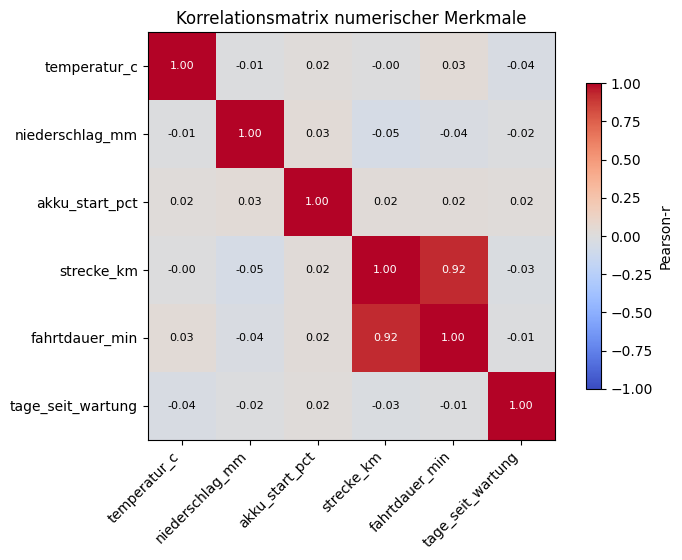

In [28]:
# Numerische Variablen vergleichen
spalten = ['temperatur_c', 'niederschlag_mm', 'akku_start_pct',
           'strecke_km', 'fahrtdauer_min', 'tage_seit_wartung']
korrelation = plausibel[spalten].corr(numeric_only=True)
display(korrelation.round(2))

fig, ax = plt.subplots(figsize=(7.5, 5.7))
im = ax.imshow(korrelation, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(spalten)), labels=spalten, rotation=45, ha='right')
ax.set_yticks(range(len(spalten)), labels=spalten)
for i in range(len(spalten)):
    for j in range(len(spalten)):
        ax.text(j, i, f'{korrelation.iloc[i,j]:.2f}',
                ha='center', va='center', fontsize=8,
                color='white' if abs(korrelation.iloc[i,j]) > 0.55 else 'black')
fig.colorbar(im, ax=ax, label='Pearson-r', shrink=0.75)
ax.set_title('Korrelationsmatrix numerischer Merkmale')
plt.tight_layout()
plt.show()

### 7.3 Scatterplot nach einer Kategorie unterscheiden

Neben der Beziehung zweier numerischer Variablen kann eine **kategoriale Gruppierung** zusätzliche Muster sichtbar machen. Vergleichen Sie dazu die Strecke und Fahrtdauer nach Ausleihgebiet.

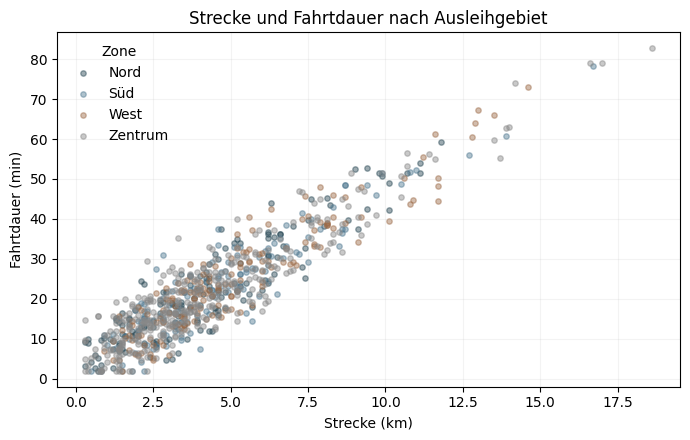

In [29]:
# Streudiagramm mit farblicher Trennung der Ausleihgebiete
fig, ax = plt.subplots(figsize=(7, 4.5))
farben = ['#264653', '#4f7890', '#9c6b48', '#888888']
for (zone, gruppe), farbe in zip(plausibel.groupby('zone', dropna=True, observed=True), farben):
    g = gruppe[['strecke_km', 'fahrtdauer_min']].dropna()
    ax.scatter(g['strecke_km'], g['fahrtdauer_min'], s=15,
               alpha=0.45, label=str(zone), color=farbe)
ax.set(xlabel='Strecke (km)', ylabel='Fahrtdauer (min)',
       title='Strecke und Fahrtdauer nach Ausleihgebiet')
ax.legend(title='Zone', frameon=False)
ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

### 7.4 Bivariate Beziehungen bei kategorialen Merkmalen

Die Kreuztabelle stellt die Häufigkeiten von Kundenstatus und Reklamation dar. Das folgende Diagramm zeigt ergänzend die **Reklamationsanteile je Kundenstatus** – damit sind auch unterschiedlich große Gruppen vergleichbar.

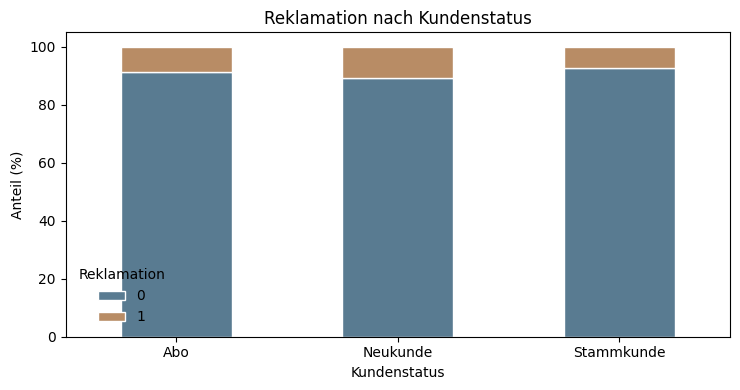

In [30]:
# Reklamationsanteil nach Kundenstatus visualisieren
anteile = pd.crosstab(
    eda['kundenstatus'], eda['reklamation_7tage'], normalize='index'
).mul(100)
ax = anteile.plot(kind='bar', stacked=True, figsize=(7.5, 4),
                  color=['#597b91', '#b88c65'], edgecolor='white')
ax.set(xlabel='Kundenstatus', ylabel='Anteil (%)',
       title='Reklamation nach Kundenstatus')
ax.legend(title='Reklamation', frameon=False)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Frage: Welche Variable eignet sich als Zielvariable?

### Arbeitsauftrag: Bivariate EDA

1. Beschreiben Sie den Zusammenhang zwischen `strecke_km` und `fahrtdauer_min` anhand des Scatterplots. Ist dieser linear?
2. Wählen Sie aus der Korrelationsmatrix ein Featurepaar mit einem relativ starken und eines mit einem schwachen linearen Zusammenhang. Vergleichen Sie die Streudiagramme.
3. Prüfen Sie, ob sich im nach `zone` eingefärbten Scatterplot systematische Unterschiede erkennen lassen.
4. Interpretieren Sie die Reklamationsanteile nach Kundenstatus. Warum sind prozentuale Häufigkeiten hier besonders hilfreich?
5. Nennen Sie eine Eigenschaft der Daten, die ein Korrelationskoeffizient allein nicht zeigt.

In [ ]:
# Eigene Auswertung der bivariaten Zusammenhänge
# Probieren Sie beispielsweise weitere Paare mit ax.scatter(...) aus.


## 8. Feature Engineering: aus vorhandenen Daten neue Merkmale erzeugen

Feature Engineering verändert die Darstellung der Merkmale oder erzeugt neue Merkmale aus vorhandenen Informationen. Hier üben wir drei Beispiele: Kategorien aus metrischen Werten, Datumsmerkmale und binäre Kodierungen.


In [ ]:
features = eda.copy()

# Beispiel: aus Temperatur eine geordnete Temperaturklasse machen
features['temperaturklasse'] = pd.cut(
    features['temperatur_c'],
    bins=[-np.inf, 0, 15, 25, np.inf],
    labels=['frostig', 'kühl', 'mild', 'warm']
)
print('Temperaturklassen:')
display(features[['temperatur_c', 'temperaturklasse']].head(8))
print('\nHäufigkeiten:')
display(features['temperaturklasse'].value_counts(dropna=False))


In [ ]:
## Interaktionseffekt Fahrdauer x Akkuladung
features['fahrdauerxakkuladung'] = features['akku_start_pct'] * features['fahrtdauer_min']

### 8.1 One-Hot-Encoding und Dummy-Kodierung

Eine nominale Variable darf nicht ohne Begründung als Zahlenskala wie `Nord = 1`, `West = 2` verwendet werden. Die Zahlen würden eine künstliche Reihenfolge nahelegen.

Für eine Variable mit **k Kategorien** unterscheiden wir in diesem Kurs:

- **Vollständiges One-Hot-Encoding:** k Indikatorspalten; jede Beobachtung besitzt genau eine 1.
- **Dummy-Kodierung mit Referenzkategorie:** k − 1 Indikatorspalten; die Referenzkategorie wird durch lauter Nullen dargestellt.

Die Bezeichnungen werden in manchen Veröffentlichungen auch synonym benutzt. Entscheidend ist, ob eine Referenzspalte weggelassen wird. Bei linearer Regression **mit Achsenabschnitt** verhindert das Weglassen einer Referenzkategorie die durch die vollständige Kodierung verursachte perfekte lineare Abhängigkeit.


In [ ]:
# Ein sehr kleines Beispiel passend zur Paper-and-Pencil-Aufgabe
beispiel = pd.DataFrame({'zone': ['Zentrum','Nord','Süd','Zentrum','Süd','Nord']})
alle_spalten = pd.get_dummies(beispiel['zone'], prefix='zone', dtype=int)
# Die Referenz wird explizit als Zentrum gewählt:
mit_referenz = alle_spalten.drop(columns='zone_Zentrum')
print('Ausgangsdaten:')
display(beispiel)
print('Vollständiges One-Hot-Encoding – 3 Spalten:')
display(alle_spalten)
print('Dummy-Kodierung – 2 Spalten, Referenz Zentrum:')
display(mit_referenz)


In [ ]:
# Übertragung auf den vollständigen UrbanBike-Datensatz:
# Fehlende Zonen werden hier vorab entfernt, damit sie nicht mit der Referenz verwechselt werden.
zonen = eda['zone'].dropna().astype(str)
onehot = pd.get_dummies(zonen, prefix='zone', dtype=int)
dummies = onehot.drop(columns='zone_Zentrum')
print('Vorhandene Zonen:', sorted(zonen.unique()))
print('Spalten One-Hot:', onehot.columns.tolist())
print('Spalten Dummy (Referenz Zentrum):', dummies.columns.tolist())
display(pd.concat([zonen.rename('zone'), onehot], axis=1).head())


### 8.2 Weitere einfache Transformationen

- Mit `astype()` können Datentypen geändert werden.
- Mit `pd.to_numeric(..., errors='coerce')` werden Zahlen aus Text umgewandelt; unlesbare Eingaben ergeben fehlende Werte.
- Mit `fillna()` lassen sich fehlende Werte für **eine konkrete Analyse** ersetzen. Die Wahl eines Ersatzwertes muss fachlich begründet werden.


In [ ]:
print('Kundenstatus ist jetzt:', eda['kundenstatus'].dtype)

mit_median = eda[['temperatur_c']].copy()
median_temp = mit_median['temperatur_c'].median()
mit_median['temperatur_ersetzt'] = mit_median['temperatur_c'].fillna(median_temp)
print('Fehlende Temperaturen vorher:', mit_median['temperatur_c'].isna().sum())
print('Fehlende Temperaturen danach:', mit_median['temperatur_ersetzt'].isna().sum())
print('Für diese Demonstration eingesetzter Median:', round(median_temp,2))


## 9. Übungen


Die Aufgaben beziehen sich genau auf die Daten aus dem Paket. 


### Aufgabe 1 – Spalten- und Zellzugriff

a) Geben Sie die vollständige Spalte `zone` aus.  
b) Geben Sie die beiden Spalten `zone` und `temperatur_c` zusammen aus.  
c) Geben Sie mit `iloc` den Wert aus der dritten Zeile und der sechsten Spalte aus.  
d) Erläutern Sie kurz den Unterschied zwischen `loc` und `iloc`.

In [ ]:
# Ihre Lösung: Aufgabe 1
# TODO: Ersetzen Sie pass durch Ihre Befehle und notieren Sie die Erklärung.
pass


### Aufgabe 2 – Datenqualität

a) Ermitteln Sie die Anzahl fehlender Werte in `temperatur_c`.  
b) Wie viele exakt doppelte Zeilen enthält der Datensatz?  
c) Welcher Kundenstatus wurde zunächst nicht als fehlend erkannt und wie kann man das korrigieren?

In [ ]:
# Ihre Lösung: Aufgabe 2
# TODO
pass


### Aufgabe 3 – Deskriptive Statistik

a) Ermitteln Sie Mittelwert und Median der Fahrtdauer.  
b) Erzeugen Sie eine Kennzahlentabelle mit `describe()`.  
c) Warum ist der Median bei einem rechtsschiefen Datensatz häufig sinnvoll?

In [ ]:
# Ihre Lösung: Aufgabe 3
# TODO
pass


### Aufgabe 4 – Kategoriale Variable

Ermitteln Sie die absoluten und relativen Häufigkeiten der Ausleihgebiete. Welche Zone kommt am häufigsten vor? Sind alle Zonenwerte vorhanden?

In [ ]:
# Ihre Lösung: Aufgabe 4
# TODO
pass


### Aufgabe 5 – Feature Engineering

Leiten Sie aus `startzeit` eine neue Variable `monat` ab. Ordnen Sie anschließend jede Buchung einem Monat zu und geben Sie die Buchungszahlen je Monat aus.

In [ ]:
# Ihre Lösung: Aufgabe 5
# TODO
pass


### Aufgabe 6 – One-Hot vs. Dummy

a) Erstellen Sie für die sechs Zonenwerte `Zentrum`, `Nord`, `Süd`, `Zentrum`, `Süd`, `Nord` die vollständige One-Hot-Kodierung.  
b) Erstellen Sie eine Dummy-Kodierung, bei der `Zentrum` die Referenzkategorie ist.  
c) Erläutern Sie den Unterschied zwischen den beiden Kodierungen (auch auf Papier möglich).

In [ ]:
# Ihre Lösung: Aufgabe 6
# TODO
pass


### Aufgabe 7 – Interpretation

Untersuchen Sie, ob sich die mittlere Fahrtdauer zwischen den Zonen unterscheidet. Berechnen Sie die Mittelwerte mit `groupby()`. Formulieren Sie einen vorsichtigen Satz zur Interpretation der Unterschiede.

In [ ]:
# Ihre Lösung: Aufgabe 7
# TODO
pass


### Aufgabe 8 – Python-Typen am Datensatz 

Erstellen Sie aus `df` eine Liste der ersten drei Werte von `temperatur_c`. Geben Sie das zweite Element aus. Erzeugen Sie anschließend eine Menge (`set`) der vorkommenden Werte von `zone`. Geben Sie deren Anzahl aus. **Hinweis:** Python-Indizes beginnen bei 0.


In [ ]:
# Ihre Lösung: Aufgabe 8
# TODO
pass

### Aufgabe 9 – Merkmale unterscheiden und transformieren

Erläutern Sie den Unterschied zwischen `object`, `category`, `datetime64` und `bool`. Erzeugen Sie aus der Variablen `reklamation_7tage` eine neue boolesche Spalte. Bestimmen Sie außerdem die mittlere Zeichenlänge der vorhandenen Feedbacktexte.


In [ ]:
# Ihre Lösung: Aufgabe 9
# TODO
pass

## 10. Reflexion

**Weitere Übungsfragen:**

1. Warum sind `fahrrad_id` und `zone` trotz ihrer Speicherung als Text nicht derselbe Merkmalstyp?
2. Warum darf ein negativer Wert in `strecke_km` nicht unbesehen in eine Auswertung übernommen werden?
3. Was zeigt ein Histogramm, was eine Häufigkeitstabelle?
4. Warum bedeutet ein Korrelationskoeffizient nahe 0 nicht, dass überhaupt kein Zusammenhang vorliegt?
5. Wie viele Indikatorspalten entstehen bei fünf Kategorien beim vollständigen One-Hot-Encoding und bei der Referenzkodierung?

**Merksatz:** Die EDA beschreibt und prüft vorhandene Daten. Feature Engineering verändert ihre Darstellung oder erzeugt neue Merkmale. Beide Schritte müssen fachlich nachvollziehbar sein.

*Ende des Tutorials.*
